In [33]:
import numpy as np
import pandas as pd

inputfile = 'C:/Users/lenovo/Desktop/data3.csv' # 输入的数据文件
data = pd.read_csv(inputfile) # 读取数据

# 描述性统计分析
# 依次计算最小值、最大值、均值、标准差
desc = [data.min(), data.max(), data.mean(), data.std()]
# 将结果存入DataFrame
desc = pd.DataFrame(desc, index = ['Min', 'Max', 'Mean', 'STD']).T
np.round(desc, 2) # 保留两位小数

,Min,Max,Mean,STD
x1,3831732.00,7599295.00,5579519.95,1262194.72
x2,181.54,2110.78,765.04,595.70
x3,448.19,6882.85,2370.83,1919.17
x4,7571.00,42049.14,19644.69,10203.02
x5,6212.70,33156.83,15870.95,8199.77
x6,6370241.00,8323096.00,7350513.60,621341.85
x7,525.71,4454.55,1712.24,1184.71
x8,985.31,15420.14,5705.80,4478.40
x9,60.62,228.46,129.49,50.51
x10,65.66,852.56,340.22,251.58


In [8]:
# 计算相关系数矩阵
corr = data.corr(method = 'pearson')
# 保留两位小数 
np.round(corr, 2)

,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,x11,x12,x13,y
x1,1.00,0.95,0.95,0.97,0.97,0.99,0.95,0.97,0.98,0.98,-0.29,0.94,0.96,0.94
x2,0.95,1.00,1.00,0.99,0.99,0.92,0.99,0.99,0.98,0.98,-0.13,0.89,1.00,0.98
x3,0.95,1.00,1.00,0.99,0.99,0.92,1.00,0.99,0.98,0.99,-0.15,0.89,1.00,0.99
x4,0.97,0.99,0.99,1.00,1.00,0.95,0.99,1.00,0.99,1.00,-0.19,0.91,1.00,0.99
x5,0.97,0.99,0.99,1.00,1.00,0.95,0.99,1.00,0.99,1.00,-0.18,0.90,0.99,0.99
x6,0.99,0.92,0.92,0.95,0.95,1.00,0.93,0.95,0.97,0.96,-0.34,0.95,0.94,0.91
x7,0.95,0.99,1.00,0.99,0.99,0.93,1.00,0.99,0.98,0.99,-0.15,0.89,1.00,0.99
x8,0.97,0.99,0.99,1.00,1.00,0.95,0.99,1.00,0.99,1.00,-0.15,0.90,1.00,0.99
x9,0.98,0.98,0.98,0.99,0.99,0.97,0.98,0.99,1.00,0.99,-0.23,0.91,0.99,0.98
x10,0.98,0.98,0.99,1.00,1.00,0.96,0.99,1.00,0.99,1.00,-0.17,0.90,0.99,0.99


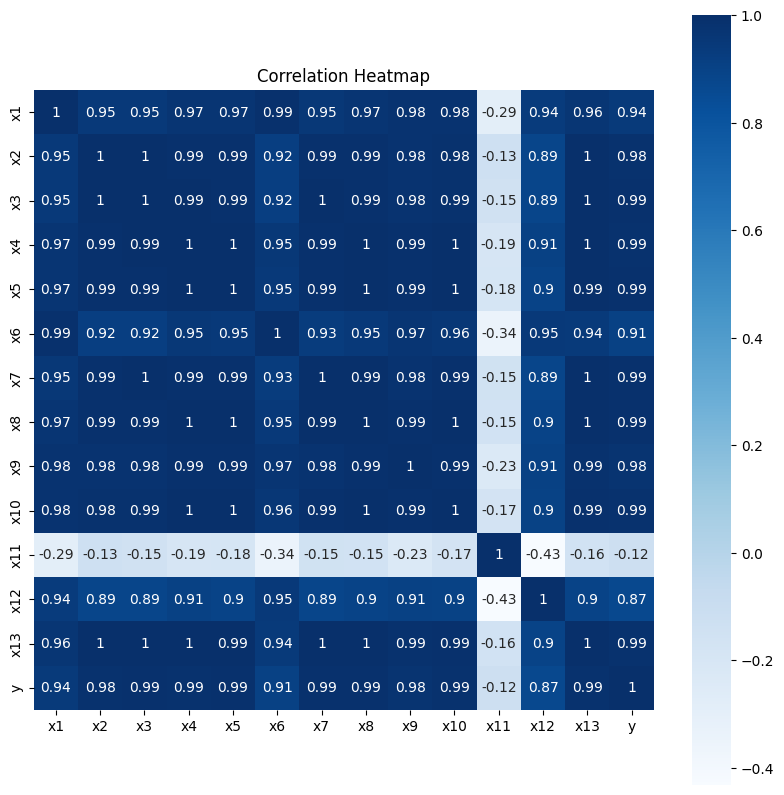

In [9]:
import matplotlib.pyplot as plt
# 使用seaborn进行可视化
import seaborn as sns
# 设置画布大小
plt.subplots(figsize=(10, 10))  
sns.heatmap(corr, annot=True, vmax=1, square=True, cmap="Blues") 
plt.title('Correlation Heatmap')
plt.show()

In [11]:
import numpy as np
import pandas as pd
from sklearn.linear_model import Lasso
import warnings
warnings.filterwarnings("ignore")
inputfile = 'C:/Users/lenovo/Desktop/data3.csv'  # 输入的数据文件
data = pd.read_csv(inputfile)  # 读取数据

#********** begin **********/
# 调用Lasso()函数，设置λ的值为1000
lasso = Lasso(1000) 
lasso.fit(data.iloc[:,0:13],data['y'])

# 输出结果，保留4位小数
print('相关系数:',np.round(lasso.coef_,4))
# 计算相关系数非零的个数
print('相关系数非零个数:',np.sum(lasso.coef_ != 0))
# 返回一个相关系数是否为零的布尔数组
mask = lasso.coef_ != 0  
print('相关系数是否为零:',mask)

# 输出的数据文件
outputfile ='new_reg_data.csv'
# 返回相关系数非零的数据
new_reg_data = data.iloc[:, 0:13].iloc[:, mask] 
# 存储数据
new_reg_data.to_csv(outputfile, index=False) 
print('输出数据的维度:',new_reg_data.shape)  # 查看输出数据的维度
# 选中的列
selected_columns = new_reg_data.columns
print('选中的列：',selected_columns)
#********** end **********/
new_reg_data.head(5)

相关系数: [-2.000e-04 -0.000e+00  1.241e-01 -1.030e-02  6.540e-02  1.000e-04
  3.174e-01  3.490e-02 -0.000e+00  0.000e+00  0.000e+00  0.000e+00
 -4.030e-02]
相关系数非零个数: 8
相关系数是否为零: [ True False  True  True  True  True  True  True False False False False
  True]
输出数据的维度: (20, 8)
选中的列： Index(['x1', 'x3', 'x4', 'x5', 'x6', 'x7', 'x8', 'x13'], dtype='object')


,x1,x3,x4,x5,x6,x7,x8,x13
0,3831732,448.19,7571.00,6212.70,6370241,525.71,985.31,5321
1,3913824,549.97,9038.16,7601.73,6467115,618.25,1259.20,6529
2,3928907,686.44,9905.31,8092.82,6560508,638.94,1468.06,7008
3,4282130,802.59,10444.60,8767.98,6664862,656.58,1678.12,7694
4,4453911,904.57,11255.70,9422.33,6741400,758.83,1893.52,8027


In [12]:
new_reg_data['year'] = range(1994, 2014)
new_reg_data.set_index('year', inplace=True)
new_reg_data.tail(5)

,x1,x3,x4,x5,x6,x7,x8,x13
year,,,,,,,,
2009,6791495,3615.77,27609.59,22820.89,7946154,2659.85,9138.21,24190
2010,7110695,4476.38,30658.49,25011.61,8061370,3263.57,10748.28,29549
2011,7431755,5243.03,34438.08,28209.74,8145797,3412.21,12423.44,34214
2012,7512997,5977.27,38053.52,30490.44,8222969,3758.39,13551.21,37934
2013,7599295,6882.85,42049.14,33156.83,8323096,4454.55,15420.14,41972


In [13]:
# 增加2014，2015两行，用来存储预测结果
new_reg_data.loc[2014] = None
new_reg_data.loc[2015] = None
new_reg_data.tail(5)

,x1,x3,x4,x5,x6,x7,x8,x13
year,,,,,,,,
2011,7431755.0,5243.03,34438.08,28209.74,8145797.0,3412.21,12423.44,34214.0
2012,7512997.0,5977.27,38053.52,30490.44,8222969.0,3758.39,13551.21,37934.0
2013,7599295.0,6882.85,42049.14,33156.83,8323096.0,4454.55,15420.14,41972.0
2014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [14]:
def gm11(x0, predict_steps):
    """
    GM(1,1)灰色预测函数
    参数：
    - x0: 原始时间序列（一维数组，如1994-2013年的某列数据）
    - predict_steps: 要预测的步数（这里需预测2014、2015，即predict_steps=2）
    返回：
    - x0_pred: 包含原始序列+预测结果的完整序列
    """
    # 1. 累加生成序列X(1)
    x1 = x0.cumsum()
    # 2. 构造紧邻均值生成序列Z(1)
    z1 = (x1[:-1] + x1[1:]) / 2.0
    z1 = z1.reshape(-1, 1)
    # 3. 构造矩阵B和向量Y，最小二乘法求解参数a、b
    B = np.hstack([-z1, np.ones_like(z1)])
    Y = x0[1:].reshape(-1, 1)
    params = np.linalg.inv(B.T @ B) @ B.T @ Y  # 矩阵运算求解a, b
    a, b = params[0, 0], params[1, 0]
    # 4. 构建预测模型，生成X(1)的预测值
    x1_pred = np.zeros(len(x0) + predict_steps)
    x1_pred[0] = x0[0]  # X(1)的第一个值=X(0)的第一个值
    # 拟合已有数据
    for k in range(len(x0)-1):
        x1_pred[k+1] = (x0[0] - b/a) * np.exp(-a * k) + b/a
    # 预测未来步数
    for k in range(len(x0)-1, len(x0)-1 + predict_steps):
        x1_pred[k+1] = (x0[0] - b/a) * np.exp(-a * k) + b/a
    # 5. 累减生成X(0)的预测值（还原原始序列）
    x0_pred = np.zeros_like(x1_pred)
    x0_pred[0] = x1_pred[0]
    x0_pred[1:] = x1_pred[1:] - x1_pred[:-1]
    return x0_pred

In [15]:
# 要预测的特征列
target_cols = ['x1', 'x3', 'x4', 'x5', 'x6', 'x7', 'x8', 'x13']

for col in target_cols:
    # 提取1994-2013年的原始序列
    x0 = new_reg_data.loc[1994:2013, col].values
    # 预测2步（2014、2015）
    x0_pred = gm11(x0, predict_steps=2)
    # 填充2014、2015年的预测值
    new_reg_data.loc[2014, col] = x0_pred[20]  # 第21个值对应2014
    new_reg_data.loc[2015, col] = x0_pred[21]  # 第22个值对应2015

# 查看填充后的结果
new_reg_data.tail(5)

,x1,x3,x4,x5,x6,x7,x8,x13
year,,,,,,,,
2011,7.431755e+06,5243.030000,34438.080000,28209.740000,8.145797e+06,3412.210000,12423.440000,34214.000000
2012,7.512997e+06,5977.270000,38053.520000,30490.440000,8.222969e+06,3758.390000,13551.210000,37934.000000
2013,7.599295e+06,6882.850000,42049.140000,33156.830000,8.323096e+06,4454.550000,15420.140000,41972.000000
2014,7.835785e+06,6072.570152,39797.126328,31999.244927,8.385620e+06,4058.411541,16260.098605,39659.446340
2015,8.142148e+06,7042.313018,43611.843582,35046.625962,8.505523e+06,4600.404822,18686.277051,44506.471782


In [16]:
# 提取财政收入列，合并至新数据框中
y = list(data['y'].values) 
y.extend([np.nan,np.nan])
new_reg_data['y'] = y
new_reg_data.tail(5)

,x1,x3,x4,x5,x6,x7,x8,x13,y
year,,,,,,,,,
2011,7.431755e+06,5243.030000,34438.080000,28209.740000,8.145797e+06,3412.210000,12423.440000,34214.000000,1535.14
2012,7.512997e+06,5977.270000,38053.520000,30490.440000,8.222969e+06,3758.390000,13551.210000,37934.000000,1579.68
2013,7.599295e+06,6882.850000,42049.140000,33156.830000,8.323096e+06,4454.550000,15420.140000,41972.000000,2088.14
2014,7.835785e+06,6072.570152,39797.126328,31999.244927,8.385620e+06,4058.411541,16260.098605,39659.446340,NaN
2015,8.142148e+06,7042.313018,43611.843582,35046.625962,8.505523e+06,4600.404822,18686.277051,44506.471782,NaN


In [28]:
# 灰色预测后保存的路径
outputfile = 'C:/Users/lenovo/Desktop/new_reg_data_GM11.csv'
 # 结果输出
new_reg_data.to_csv(outputfile)

In [30]:
import matplotlib.pyplot as plt
from sklearn.svm import LinearSVR

inputfile = 'C:/Users/lenovo/Desktop/new_reg_data_GM11.csv'  # 灰色预测后保存的路径
data = pd.read_csv(inputfile)  # 读取数据
data.set_index('year', inplace=True)
data.tail(5)

,x1,x3,x4,x5,x6,x7,x8,x13,y
year,,,,,,,,,
2011,7.431755e+06,5243.030000,34438.080000,28209.740000,8.145797e+06,3412.210000,12423.440000,34214.000000,1535.14
2012,7.512997e+06,5977.270000,38053.520000,30490.440000,8.222969e+06,3758.390000,13551.210000,37934.000000,1579.68
2013,7.599295e+06,6882.850000,42049.140000,33156.830000,8.323096e+06,4454.550000,15420.140000,41972.000000,2088.14
2014,7.835785e+06,6072.570152,39797.126328,31999.244927,8.385620e+06,4058.411541,16260.098605,39659.446340,NaN
2015,8.142148e+06,7042.313018,43611.843582,35046.625962,8.505523e+06,4600.404822,18686.277051,44506.471782,NaN


In [31]:
# 属性所在列
feature = selected_columns

# 取2014年前的数据建模
data_train = data.loc[range(1994,2014)].copy() 
data_mean = data_train.mean()
data_std = data_train.std()
data_train = (data_train - data_mean)/data_std  # 数据标准化

# 使用 .values 替代 .as_matrix()
x_train = data_train[feature].values  # 属性数据
y_train = data_train['y'].values  # 标签数据

linearsvr = LinearSVR()  # 调用LinearSVR()函数
linearsvr.fit(x_train, y_train)

# 预测，并还原结果
x = ((data[feature] - data_mean[feature])/data_std[feature]).values
data['y_pred'] = linearsvr.predict(x) * data_std['y'] + data_mean['y']

outputfile = 'new_reg_data_GM11_revenue.xlsx'  # SVR预测后保存的结果
data.to_excel(outputfile)
print('真实值与预测值分别为：\n')
print(data[['y','y_pred']])

真实值与预测值分别为：

            y       y_pred
year                      
1994    64.87    38.523317
1995    99.75    85.031887
1996    88.11    95.867887
1997   106.07   107.377583
1998   137.32   151.812763
1999   188.14   188.796832
2000   219.91   219.938603
2001   271.91   230.689133
2002   269.10   220.087959
2003   300.55   300.803919
2004   338.45   383.594049
2005   408.86   463.098164
2006   476.72   554.634259
2007   838.99   691.009791
2008   843.14   842.455343
2009  1107.67  1086.863459
2010  1399.16  1377.832126
2011  1535.14  1535.140000
2012  1579.68  1737.346117
2013  2088.14  2083.641311
2014      NaN  1878.881833
2015      NaN  2185.979582


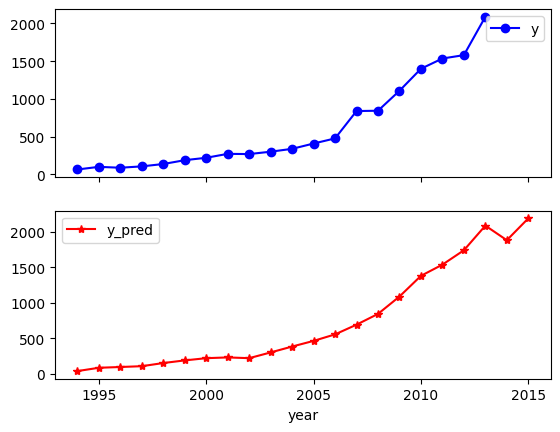

In [32]:
fig = data[['y','y_pred']].plot(subplots = True, style=['b-o','r-*'])  # 画出预测结果图
plt.show()